# 1. Judul dan Tujuan Eksperimen
## **ApiWaspada: Eksperimen Pelatihan & Evaluasi Model YOLO untuk Deteksi Visual Api dan Asap (D-Fire Dataset)**

### **Tujuan Eksperimen**
1. Memeriksa dan memvalidasi struktur **D-Fire Dataset** ([GitHub - gaia-solutions-on-demand/DFireDataset](https://github.com/gaia-solutions-on-demand/DFireDataset) & [Dokumentasi Resmi D-Fire](https://gaia-solutions-on-demand.github.io/DFireDataset/)) secara nyata di disk.
2. Memverifikasi format anotasi YOLO (`<class_id> <x_center> <y_center> <width> <height>`) dan mengidentifikasi pemetaan kelas (`smoke` vs `fire`) berdasarkan metadata aktual tanpa asumsi buta.
3. Melakukan *transfer learning* menggunakan **Ultralytics YOLO** dengan dukungan perangkat **GPU NVIDIA (CUDA)** maupun **CPU**.
4. Mengevaluasi performa model secara terpisah pada *validation set* dan *test set* menggunakan metrik **Precision**, **Recall**, **mAP@0.5**, **mAP@0.5:0.95**, **Confusion Matrix**, dan **Precision-Recall Curve**.
5. Menyimpan bobot model terbaik ke `ml/weights/best.pt` agar langsung terintegrasi dengan backend **FastAPI ApiWaspada Kota Jambi**.

# 2. Import Library
Mengimpor seluruh pustaka standar Python, pemrosesan citra (`cv2`, `PIL`), komputasi numerik (`numpy`), visualisasi (`matplotlib`), konfigurasi (`yaml`), serta modul internal `ml/` ApiWaspada.

In [1]:
import os
import sys
import json
import shutil
import random
import platform
from pathlib import Path
from collections import Counter

import yaml
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "ml":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Direktori Root Project: {PROJECT_ROOT}")

Direktori Root Project: D:\ApiWaspada_argon


# 3. Pemeriksaan Versi Python
Memeriksa versi interpreter Python dan sistem operasi untuk memastikan kompatibilitas lingkungan pengembangan (direkomendasikan Python 3.10+ pada Windows 10/11).

In [2]:
print("=" * 60)
print(f"Versi Python     : {sys.version}")
print(f"Versi Tuple      : {sys.version_info.major}.{sys.version_info.minor}.{sys.version_info.micro}")
print(f"Sistem Operasi   : {platform.system()} {platform.release()} ({platform.machine()})")
print(f"Executable Path  : {sys.executable}")
print("=" * 60)

if sys.version_info < (3, 10):
    print("[PERINGATAN] Versi Python di bawah 3.10. Disarankan menggunakan Python 3.10.")
else:
    print("[OK] Versi Python kompatibel dengan spesifikasi ApiWaspada.")

Versi Python     : 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
Versi Tuple      : 3.10.11
Sistem Operasi   : Windows 10 (AMD64)
Executable Path  : c:\Users\Alya Rafina\AppData\Local\Programs\Python\Python310\python.exe
[OK] Versi Python kompatibel dengan spesifikasi ApiWaspada.


# 4. Pemeriksaan Library
Memeriksa ketersediaan dan versi pustaka utama AI & Computer Vision (`torch`, `ultralytics`, `cv2`, `numpy`, `PIL`, `matplotlib`, `yaml`).

In [3]:
REQUIRED_LIBRARIES = [
    ("torch", "PyTorch"),
    ("ultralytics", "Ultralytics YOLO"),
    ("cv2", "OpenCV"),
    ("numpy", "NumPy"),
    ("PIL", "Pillow"),
    ("matplotlib", "Matplotlib"),
    ("yaml", "PyYAML"),
]

library_status = {}
for mod_name, label in REQUIRED_LIBRARIES:
    try:
        mod = __import__(mod_name)
        ver = getattr(mod, "__version__", "tersedia")
        library_status[mod_name] = True
        print(f"[TERSEDIA] {label:<20} ({mod_name}) : v{ver}")
    except ImportError:
        library_status[mod_name] = False
        print(f"[BELUM TERINSTAL] {label:<13} ({mod_name}) : Jalankan `pip install -r requirements.txt`")

[TERSEDIA] PyTorch              (torch) : v2.14.1+cpu
[TERSEDIA] Ultralytics YOLO     (ultralytics) : v8.4.197
[TERSEDIA] OpenCV               (cv2) : v4.13.0
[TERSEDIA] NumPy                (numpy) : v2.2.6
[TERSEDIA] Pillow               (PIL) : v11.3.0
[TERSEDIA] Matplotlib           (matplotlib) : v3.10.9
[TERSEDIA] PyYAML               (yaml) : v6.0.3


# 5. Pemeriksaan Perangkat CPU/GPU
Mendeteksi ketersediaan akselerasi GPU NVIDIA (CUDA) melalui PyTorch. Jika CUDA tidak tersedia, pipeline otomatis menggunakan `cpu`.

In [4]:
COMPUTE_DEVICE = "cpu"
if library_status.get("torch"):
    import torch
    cuda_ready = torch.cuda.is_available()
    print(f"PyTorch CUDA Available : {cuda_ready}")
    if cuda_ready:
        COMPUTE_DEVICE = "0"
        gpu_count = torch.cuda.device_count()
        gpu_name = torch.cuda.get_device_name(0)
        vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
        print(f"Jumlah GPU Terdeteksi  : {gpu_count}")
        print(f"Nama Perangkat GPU     : {gpu_name} ({vram_gb:.2f} GB VRAM)")
    else:
        print("Info: GPU NVIDIA CUDA tidak terdeteksi. Pelatihan akan menggunakan CPU.")
else:
    print("Info: PyTorch belum dimuat. Default perangkat disetel ke 'cpu'.")

print(f"Device Aktif yang Digunakan: '{COMPUTE_DEVICE}'")

PyTorch CUDA Available : False
Info: GPU NVIDIA CUDA tidak terdeteksi. Pelatihan akan menggunakan CPU.
Device Aktif yang Digunakan: 'cpu'


# 6. Persiapan Lokasi Dataset
Menentukan path direktori **D-Fire Dataset** (`ml/dataset/DFireDataset`).
- Repositori resmi: [https://github.com/gaia-solutions-on-demand/DFireDataset](https://github.com/gaia-solutions-on-demand/DFireDataset)
- Dokumentasi resmi: [https://gaia-solutions-on-demand.github.io/DFireDataset/](https://gaia-solutions-on-demand.github.io/DFireDataset/)

In [5]:
# Mengarah tepat ke D:\ApiWaspada_argon\ml\dataset\data
DATASET_DIR = (PROJECT_ROOT / "ml" / "dataset" / "data").resolve()
SOURCE_DATASET_YAML = (PROJECT_ROOT / "ml" / "dataset" / "data.yaml").resolve()
DATA_YAML_PATH = (PROJECT_ROOT / "ml" / "data.yaml").resolve()
WEIGHTS_OUTPUT_PATH = (PROJECT_ROOT / "ml" / "weights" / "best.pt").resolve()

# Jika ada data.yaml di ml/dataset/data.yaml, salin juga ke dalam ml/dataset/data/
# agar check_dataset.py membaca pemetaan kelas asli dari dataset Anda
if SOURCE_DATASET_YAML.exists() and DATASET_DIR.exists():
    shutil.copy2(SOURCE_DATASET_YAML, DATASET_DIR / "data.yaml")

print(f"Lokasi Target D-Fire Dataset : {DATASET_DIR}")
print(f"File YAML Bawaan Dataset     : {SOURCE_DATASET_YAML} (Ada: {SOURCE_DATASET_YAML.exists()})")
print(f"Lokasi Konfigurasi data.yaml : {DATA_YAML_PATH}")
print(f"Lokasi Output Model Terbaik  : {WEIGHTS_OUTPUT_PATH}")

if not DATASET_DIR.exists():
    print("\n[INFO] Folder dataset belum ditemukan di lokasi tersebut.")
else:
    splits_found = [p.name for p in DATASET_DIR.iterdir() if p.is_dir()]
    print(f"\n[OK] Direktori dataset ditemukan! Subfolder terdeteksi: {splits_found}")

Lokasi Target D-Fire Dataset : D:\ApiWaspada_argon\ml\dataset\data
File YAML Bawaan Dataset     : D:\ApiWaspada_argon\ml\dataset\data.yaml (Ada: True)
Lokasi Konfigurasi data.yaml : D:\ApiWaspada_argon\ml\data.yaml
Lokasi Output Model Terbaik  : D:\ApiWaspada_argon\ml\weights\best.pt

[OK] Direktori dataset ditemukan! Subfolder terdeteksi: ['test', 'train', 'val']


# 7. Pemeriksaan Struktur Dataset
Memanggil modul `ml/check_dataset.py` untuk memeriksa struktur sub-folder (`train`, `val`, `test`, `images`, `labels`) yang benar-benar ada di disk.

In [6]:
from ml.check_dataset import check_dataset, create_validation_split_from_train

dataset_report = check_dataset(
    dataset_dir=DATASET_DIR,
    output_yaml_path=None,
    auto_create_val=False,
)

print(json.dumps(dataset_report, indent=2, ensure_ascii=False))

{
  "dataset_ready": true,
  "dataset_dir": "D:\\ApiWaspada_argon\\ml\\dataset\\data",
  "class_mapping": {
    "0": "smoke",
    "1": "fire"
  },
  "num_classes": 2,
  "splits": {
    "train": {
      "exists": true,
      "path": "D:\\ApiWaspada_argon\\ml\\dataset\\data\\train",
      "total_images": 14122,
      "total_labels": 14122,
      "missing_labels": 0,
      "invalid_annotation_lines": 0,
      "image_categories": {
        "only_fire": 770,
        "only_smoke": 3836,
        "fire_and_smoke": 3058,
        "none": 6458
      },
      "bounding_boxes_by_class_id": {
        "1": 9638,
        "0": 7794
      },
      "bounding_boxes_by_class_name": {
        "0 (smoke)": 7794,
        "1 (fire)": 9638
      },
      "total_bounding_boxes": 17432,
      "sample_warnings": []
    },
    "val": {
      "exists": true,
      "path": "D:\\ApiWaspada_argon\\ml\\dataset\\data\\val",
      "total_images": 3099,
      "total_labels": 3099,
      "missing_labels": 0,
      "invalid_

# 8. Pemeriksaan Anotasi
Memeriksa validitas baris anotasi pada file `.txt` di setiap split (`<class_id> <x_center> <y_center> <width> <height>`), menghitung jumlah citra positif (`only_fire`, `only_smoke`, `fire_and_smoke`) serta citra negatif (`none` / label kosong), dan memeriksa apakah diperlukan konversi format.

In [7]:
if dataset_report.get("dataset_ready"):
    for split_name, info in dataset_report.get("splits", {}).items():
        if info.get("exists"):
            print(f"=== Split: {split_name.upper()} ===")
            print(f"  Total Gambar           : {info['total_images']}")
            print(f"  Total File Label (.txt): {info['total_labels']}")
            print(f"  Baris Anotasi Invalid  : {info['invalid_annotation_lines']}")
            print(f"  Kategori Gambar        : {info['image_categories']}")
            print(f"  Jumlah Bounding Box    : {info['bounding_boxes_by_class_name']}")
            if info.get("sample_warnings"):
                print(f"  Peringatan Sampel      : {info['sample_warnings'][:3]}")
else:
    print("[INFO] Melewati pemeriksaan detail file anotasi karena dataset D-Fire belum ditempatkan di folder target.")

=== Split: TRAIN ===
  Total Gambar           : 14122
  Total File Label (.txt): 14122
  Baris Anotasi Invalid  : 0
  Kategori Gambar        : {'only_fire': 770, 'only_smoke': 3836, 'fire_and_smoke': 3058, 'none': 6458}
  Jumlah Bounding Box    : {'0 (smoke)': 7794, '1 (fire)': 9638}
=== Split: VAL ===
  Total Gambar           : 3099
  Total File Label (.txt): 3099
  Baris Anotasi Invalid  : 0
  Kategori Gambar        : {'only_fire': 174, 'only_smoke': 845, 'fire_and_smoke': 705, 'none': 1375}
  Jumlah Bounding Box    : {'0 (smoke)': 1756, '1 (fire)': 2176}
=== Split: TEST ===
  Total Gambar           : 4306
  Total File Label (.txt): 4306
  Baris Anotasi Invalid  : 8
  Kategori Gambar        : {'only_fire': 220, 'only_smoke': 1186, 'fire_and_smoke': 895, 'none': 2005}
  Jumlah Bounding Box    : {'0 (smoke)': 2315, '1 (fire)': 2878}
  Peringatan Sampel      : ['WEB10769.txt:L2 koordinat di luar [0,1] ([0.50546875, 0.3625, 1.0296875, 0.7083333333333334]) - kemungkinan format piksel', 'W

# 9. Identifikasi Pemetaan Kelas
Memastikan urutan ID kelas (`0` dan `1`) sesuai dengan metadata aktual dataset dan tidak mengasumsikan secara buta. Berdasarkan dokumentasi resmi D-Fire Dataset, konvensi kelas adalah `0: smoke` dan `1: fire`.

In [8]:
CLASS_MAPPING = dataset_report.get("class_mapping", {0: "smoke", 1: "fire"})
print("Pemetaan Kelas yang Teridentifikasi:")
for cid, cname in CLASS_MAPPING.items():
    print(f"  Class ID {cid} -> '{cname}'")

Pemetaan Kelas yang Teridentifikasi:
  Class ID 0 -> 'smoke'
  Class ID 1 -> 'fire'


# 10. Visualisasi Sampel Gambar dan Bounding Box
Menampilkan sampel gambar beserta *ground-truth bounding box* dari folder dataset (jika tersedia di disk) menggunakan Matplotlib.

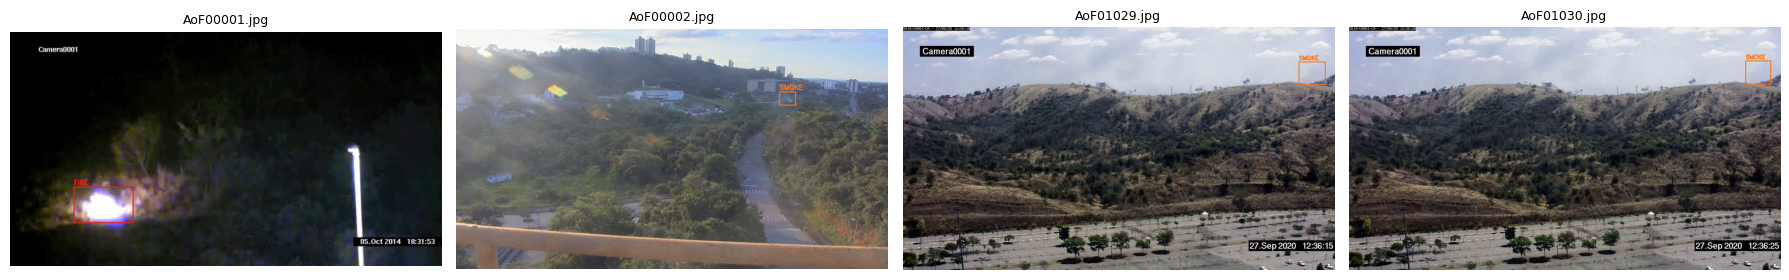

In [9]:
def visualize_dataset_samples(dataset_dir: Path, class_map: dict, max_samples: int = 4):
    train_img_dir = dataset_dir / "train" / "images"
    train_lbl_dir = dataset_dir / "train" / "labels"
    if not train_img_dir.exists():
        print("[INFO] Folder train/images belum tersedia untuk visualisasi sampel.")
        return

    all_imgs = sorted([p for p in train_img_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}])
    annotated_imgs = []
    for p in all_imgs:
        lbl = train_lbl_dir / f"{p.stem}.txt"
        if lbl.exists() and lbl.stat().st_size > 0:
            annotated_imgs.append(p)
        if len(annotated_imgs) >= max_samples:
            break

    if not annotated_imgs:
        print("[INFO] Tidak ditemukan sampel beranotasi untuk ditampilkan.")
        return

    fig, axes = plt.subplots(1, len(annotated_imgs), figsize=(4.5 * len(annotated_imgs), 4.5))
    if len(annotated_imgs) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, annotated_imgs):
        img_bgr = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        lbl_path = train_lbl_dir / f"{img_path.stem}.txt"
        for line in lbl_path.read_text(encoding="utf-8").splitlines():
            parts = line.strip().split()
            if len(parts) == 5:
                cid = int(float(parts[0]))
                xc, yc, bw, bh = [float(x) for x in parts[1:]]
                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)
                cname = class_map.get(cid, str(cid))
                color = (220, 38, 38) if "fire" in cname.lower() else (249, 115, 22)
                cv2.rectangle(img_rgb, (x1, y1), (x2, y2), color, 2)
                cv2.putText(img_rgb, cname.upper(), (x1, max(15, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
        ax.imshow(img_rgb)
        ax.set_title(img_path.name, fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

visualize_dataset_samples(DATASET_DIR, CLASS_MAPPING)

# 11. Pembuatan Konfigurasi `data.yaml`
Membuat atau memperbarui file `ml/data.yaml` agar selaras dengan lokasi dataset dan pemetaan kelas yang terverifikasi.

In [10]:
if dataset_report.get("dataset_ready"):
    val_info = dataset_report["splits"].get("val", {})
    if not val_info.get("exists") or val_info.get("total_images", 0) == 0:
        print("[INFO] Split validasi belum ditemukan. Membuat validation split (10% dari train)...")
        split_res = create_validation_split_from_train(DATASET_DIR, val_ratio=0.10, seed=42)
        print(split_res)
    dataset_report = check_dataset(DATASET_DIR, output_yaml_path=DATA_YAML_PATH)

print("Isi file ml/data.yaml saat ini:")
print(DATA_YAML_PATH.read_text(encoding="utf-8"))

Isi file ml/data.yaml saat ini:
path: D:/ApiWaspada_argon/ml/dataset/data
train: train/images
val: val/images
nc: 2
names:
  0: smoke
  1: fire
test: test/images



# 12. Pemeriksaan Split Train, Validation, dan Test
Memastikan pemisahan (*isolation*) antara data `train`, `val`, dan `test`. Data `test` tidak digunakan untuk memilih hyperparameter atau *early stopping* selama pelatihan.

In [11]:
for split_key in ("train", "val", "test"):
    s_info = dataset_report.get("splits", {}).get(split_key, {})
    status_str = "TERSEDIA" if s_info.get("exists") and s_info.get("total_images", 0) > 0 else "BELUM TERSEDIA"
    print(f"Split [{split_key.upper():<5}] : {status_str:<15} | Jumlah Gambar: {s_info.get('total_images', 0)}")

Split [TRAIN] : TERSEDIA        | Jumlah Gambar: 14122
Split [VAL  ] : TERSEDIA        | Jumlah Gambar: 3099
Split [TEST ] : TERSEDIA        | Jumlah Gambar: 4306


# 13. Training YOLO
Menjalankan pelatihan transfer learning YOLO. Tersedia dua profil konfigurasi:
- **`lightweight`** (`ml/configs/train_lightweight.yaml`): `yolov8n.pt`, `imgsz=416`, `batch=8`, `epochs=10` (ideal untuk pengujian cepat / CPU).
- **`experiment`** (`ml/configs/train_experiment.yaml`): `yolov8s.pt`, `imgsz=640`, `batch=16`, `epochs=50` (ideal untuk pelatihan penuh pada GPU NVIDIA).

In [12]:
from ml.train import load_training_config, run_training

SELECTED_PROFILE = "lightweight"
config_file = PROJECT_ROOT / "ml" / "configs" / f"train_{SELECTED_PROFILE}.yaml"
train_cfg = load_training_config(config_file)
train_cfg["data_yaml"] = str(DATA_YAML_PATH)
train_cfg["device"] = COMPUTE_DEVICE
train_cfg["project_dir"] = str(PROJECT_ROOT / "ml" / "runs" / "detect")
train_cfg["export_best_to"] = str(WEIGHTS_OUTPUT_PATH)

print("Konfigurasi Training yang Akan Dijalankan:")
print(json.dumps(train_cfg, indent=2))

training_completed = False
if dataset_report.get("dataset_ready") and library_status.get("ultralytics"):
    exit_code = run_training(train_cfg)
    training_completed = (exit_code == 0)
else:
    print("\n[INFO] Pelatihan belum dieksekusi karena dataset D-Fire atau pustaka Ultralytics belum tersedia.")

Konfigurasi Training yang Akan Dijalankan:
{
  "base_model": "yolov8n.pt",
  "data_yaml": "D:\\ApiWaspada_argon\\ml\\data.yaml",
  "imgsz": 416,
  "batch": 8,
  "epochs": 10,
  "lr0": 0.01,
  "lrf": 0.01,
  "optimizer": "auto",
  "patience": 5,
  "device": "cpu",
  "workers": 2,
  "seed": 42,
  "project_dir": "D:\\ApiWaspada_argon\\ml\\runs\\detect",
  "experiment_name": "apiwaspada_dfire_light",
  "export_best_to": "D:\\ApiWaspada_argon\\ml\\weights\\best.pt"
}
  APIWASPADA - MULAI TRAINING MODEL YOLO (D-FIRE DATASET)
  Model Dasar     : yolov8n.pt
  Konfigurasi Data: D:\ApiWaspada_argon\ml\data.yaml
  Image Size      : 416 | Batch: 8 | Epochs: 10
  Optimizer       : auto | LR0: 0.01 | Patience: 5
  Device          : cpu | Seed: 42
New https://pypi.org/project/ultralytics/8.4.210 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.197  Python-3.10.11 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-12450HX)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=F

# 14. Visualisasi Hasil Training


In [13]:
from ml.evaluate import plot_training_history_from_csv

run_folder = Path(train_cfg["project_dir"]) / str(train_cfg["experiment_name"])
results_csv_file = run_folder / "results.csv"
loss_plot_file = run_folder / "training_validation_loss_curve.png"

if results_csv_file.exists():
    ok = plot_training_history_from_csv(results_csv_file, loss_plot_file)
    if ok and loss_plot_file.exists():
        display_img = Image.open(loss_plot_file)
        plt.figure(figsize=(12, 4.8))
        plt.imshow(display_img)
        plt.axis("off")
        plt.show()
else:
    print(f"[INFO] File hasil training '{results_csv_file}' belum tersedia. Jalankan tahap Training (Bagian 13) terlebih dahulu.")

C:\Users\Alya Rafina\AppData\Local\Temp\ipykernel_26652\3376709215.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


# 15. Evaluasi Validation Set
Menghitung metrik **Precision**, **Recall**, **mAP@0.5**, dan **mAP@0.5:0.95** pada *Validation Set* menggunakan model yang telah dilatih.

In [14]:
from ml.evaluate import evaluate_model

val_eval_summary = {}
if WEIGHTS_OUTPUT_PATH.exists() and dataset_report.get("dataset_ready"):
    val_eval_summary = evaluate_model(
        weights_path=WEIGHTS_OUTPUT_PATH,
        data_yaml_path=DATA_YAML_PATH,
        split="val",
        imgsz=int(train_cfg["imgsz"]),
        batch=int(train_cfg["batch"]),
        device=COMPUTE_DEVICE,
        output_dir=PROJECT_ROOT / "ml" / "runs" / "eval",
    )
    print(json.dumps(val_eval_summary, indent=2))
else:
    print("[INFO] Evaluasi validation belum dijalankan karena model best.pt atau dataset belum tersedia.")

Ultralytics 8.4.197  Python-3.10.11 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-12450HX)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 913.5±648.4 MB/s, size: 111.5 KB)
val: Scanning D:\ApiWaspada_argon\ml\dataset\data\val\labels.cache... 3099 images, 1375 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3099/3099  0.0s
val: D:\ApiWaspada_argon\ml\dataset\data\val\images\WEB07535.jpg: corrupt JPEG restored and saved
val: D:\ApiWaspada_argon\ml\dataset\data\val\images\WEB07536.jpg: corrupt JPEG restored and saved
val: D:\ApiWaspada_argon\ml\dataset\data\val\images\WEB07539.jpg: corrupt JPEG restored and saved
val: D:\ApiWaspada_argon\ml\dataset\data\val\images\WEB07542.jpg: corrupt JPEG restored and saved
val: D:\ApiWaspada_argon\ml\dataset\data\val\images\WEB07561.jpg: corrupt JPEG restored and saved
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 388

# 16. Evaluasi Test Final (Jika Split Test Tersedia)
Menjalankan evaluasi akhir yang objektif pada *Test Set* (hanya dilakukan setelah pemilihan model selesai).

In [15]:
test_split_info = dataset_report.get("splits", {}).get("test", {})
test_eval_summary = {}

if WEIGHTS_OUTPUT_PATH.exists() and test_split_info.get("exists") and test_split_info.get("total_images", 0) > 0:
    test_eval_summary = evaluate_model(
        weights_path=WEIGHTS_OUTPUT_PATH,
        data_yaml_path=DATA_YAML_PATH,
        split="test",
        imgsz=int(train_cfg["imgsz"]),
        batch=int(train_cfg["batch"]),
        device=COMPUTE_DEVICE,
        output_dir=PROJECT_ROOT / "ml" / "runs" / "eval",
    )
    print(json.dumps(test_eval_summary, indent=2))
else:
    print("[INFO] Evaluasi test set dilewati (model best.pt atau folder test/ belum tersedia).")

Ultralytics 8.4.197  Python-3.10.11 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-12450HX)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.3±0.1 ms, read: 11.7±10.0 MB/s, size: 122.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\ApiWaspada_argon\ml\dataset\data\test\labels... 4306 images, 2005 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 4306/4306 384.4it/s 11.2s0.1s
val: D:\ApiWaspada_argon\ml\dataset\data\test\images\WEB10769.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0296875]
val: D:\ApiWaspada_argon\ml\dataset\data\test\images\WEB10775.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.015625]
val: D:\ApiWaspada_argon\ml\dataset\data\test\images\WEB11243.jpg: corrupt JPEG restored and saved
val: D:\ApiWaspada_argon\ml\dataset\d

# 17. Confusion Matrix
Menampilkan plot **Confusion Matrix** hasil evaluasi model pada dataset.

In [16]:
cm_path_str = val_eval_summary.get("artifacts", {}).get("confusion_matrix", "")
if cm_path_str and Path(cm_path_str).exists():
    cm_img = Image.open(cm_path_str)
    plt.figure(figsize=(8, 6.5))
    plt.imshow(cm_img)
    plt.title("Confusion Matrix - Evaluasi Model YOLO")
    plt.axis("off")
    plt.show()
else:
    print("[INFO] Plot Confusion Matrix akan tersedia setelah evaluasi model (Bagian 15) dijalankan.")

C:\Users\Alya Rafina\AppData\Local\Temp\ipykernel_26652\4179421006.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


# 18. Precision-Recall Curve
Menampilkan kurva **Precision-Recall (PR Curve)** hasil evaluasi model.

In [17]:
pr_path_str = val_eval_summary.get("artifacts", {}).get("pr_curve", "")
if pr_path_str and Path(pr_path_str).exists():
    pr_img = Image.open(pr_path_str)
    plt.figure(figsize=(8, 6.5))
    plt.imshow(pr_img)
    plt.title("Precision-Recall Curve - Evaluasi Model YOLO")
    plt.axis("off")
    plt.show()
else:
    print("[INFO] Plot Precision-Recall Curve akan tersedia setelah evaluasi model (Bagian 15) dijalankan.")

[INFO] Plot Precision-Recall Curve akan tersedia setelah evaluasi model (Bagian 15) dijalankan.


# 19. Prediksi Gambar Baru
Menguji inferensi pada citra baru menggunakan `ml/predict.py` / `AIDetectionService`.

In [20]:
%pip install pydantic pydantic-settings
from ml.predict import run_batch_prediction

sample_upload_dir = PROJECT_ROOT / "storage" / "uploads"
prediction_output = run_batch_prediction(
    source=sample_upload_dir,
    weights=WEIGHTS_OUTPUT_PATH,
    conf_threshold=0.25,
)
print(json.dumps(prediction_output, indent=2, ensure_ascii=False))


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached pydantic-2.14.3-py3-none-any.whl.metadata (141 kB)
  Using cached annotated_types-0.8.0-py3-none-any.whl.metadata (15 kB)
  Using cached pydantic_core-2.50.4-cp310-cp310-win_amd64.whl.metadata (6.7 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached typing_inspection-0.4.5-py3-none-any.whl.metadata (2.6 kB)
  Using cached python_dotenv-1.2.4-py3-none-any.whl.metadata (29 kB)
Using cached pydantic-2.14.3-py3-none-any.whl (494 kB)
Using cached pydantic_core-2.50.4-cp310-cp310-win_amd64.whl (2.3 MB)
Using cached annotated_types-0.8.0-py3-none-any.whl (13 kB)
Using cached python_dotenv-1.2.4-py3-none-any.whl (23 kB)
Using cached typing_extensions-4.16.0-py3-none-any.whl (45 kB)
Using cached typing_inspection-0.4.5-py3-none-any.whl (14 kB)

  Attempting uninstall: typing-extensions

    Found existing installation: typing_extensions 4.15.0

    Uninstalling typing_extensions-4.15.0:

   ---------------------------------------- 0/7 [ty

# 20. Visualisasi Hasil Prediksi
Menampilkan citra hasil anotasi *bounding box* yang disimpan di `storage/results/`.

In [21]:
results_items = prediction_output.get("results", [])
if results_items:
    first_item = results_items[0]
    rel_vis = str(first_item.get("result_visualization", "")).lstrip("/")
    vis_path = PROJECT_ROOT / rel_vis
    if vis_path.exists():
        vis_img = Image.open(vis_path)
        plt.figure(figsize=(7, 5))
        plt.imshow(vis_img)
        plt.title(f"Status: {first_item['detection_status']} (Conf: {first_item['highest_confidence']*100:.1f}%)")
        plt.axis("off")
        plt.show()
else:
    print("[INFO] Belum ada citra uji di storage/uploads/ untuk divisualisasikan.")

C:\Users\Alya Rafina\AppData\Local\Temp\ipykernel_26652\3159129551.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


# 21. Penyimpanan `best.pt`
Memverifikasi keberadaan dan ukuran file bobot terbaik di `ml/weights/best.pt` yang digunakan oleh backend FastAPI.

In [22]:
if WEIGHTS_OUTPUT_PATH.exists() and WEIGHTS_OUTPUT_PATH.stat().st_size > 1024:
    size_mb = WEIGHTS_OUTPUT_PATH.stat().st_size / (1024 * 1024)
    print(f"[SIAP DIGUNAKAN] File model ditemukan di: {WEIGHTS_OUTPUT_PATH} ({size_mb:.2f} MB)")
else:
    print(f"[BELUM TERSEDIA] File {WEIGHTS_OUTPUT_PATH} belum terbentuk.")
    print("Backend FastAPI ApiWaspada tetap dapat dijalankan dalam Mode AI Belum Aktif (Graceful Fallback).")

[SIAP DIGUNAKAN] File model ditemukan di: D:\ApiWaspada_argon\ml\weights\best.pt (6.16 MB)


# 22. Ringkasan Hasil Eksperimen
Menyusun ringkasan seluruh parameter dan metrik hasil eksperimen secara jujur tanpa angka evaluasi rekayasa.

In [23]:
experiment_summary = {
    "project": "ApiWaspada - Deteksi Visual Api & Asap Kota Jambi",
    "dataset_ready": dataset_report.get("dataset_ready", False),
    "class_mapping": CLASS_MAPPING,
    "compute_device": COMPUTE_DEVICE,
    "training_profile": SELECTED_PROFILE,
    "best_weights_available": WEIGHTS_OUTPUT_PATH.exists(),
    "validation_metrics": val_eval_summary.get("metrics", "Belum dievaluasi (menunggu training dataset D-Fire)"),
    "test_metrics": test_eval_summary.get("metrics", "Belum dievaluasi (menunggu training dataset D-Fire)"),
}
print(json.dumps(experiment_summary, indent=2, ensure_ascii=False))

{
  "project": "ApiWaspada - Deteksi Visual Api & Asap Kota Jambi",
  "dataset_ready": true,
  "class_mapping": {
    "0": "smoke",
    "1": "fire"
  },
  "compute_device": "cpu",
  "training_profile": "lightweight",
  "best_weights_available": true,
  "validation_metrics": {
    "precision": 0.68,
    "recall": 0.5891,
    "mAP_50": 0.6425,
    "mAP_50_95": 0.3453
  },
  "test_metrics": {
    "precision": 0.6546,
    "recall": 0.5711,
    "mAP_50": 0.6186,
    "mAP_50_95": 0.3306
  }
}
